# 02 · Eliminación de ruido con varios niveles (nivel avanzado)

**Objetivo:** ampliar el estudio del nivel básico (`01_ruido_basico.ipynb`) entrenando el autoencoder con **varios niveles de ruido gaussiano** y comparando lo bien que lo limpia en cada caso.

- Usamos el **autoencoder convolucional** del código de clase, porque en `01_ruido_basico.ipynb` dio menor error que el denso.
- Ruido: `imagen_ruidosa = clamp(imagen + σ · N(0, 1), 0, 1)`.
- Para cada σ entrenamos un modelo: entrada = imagen con ruido, objetivo = imagen original.
- Niveles estudiados: σ = 0.1, 0.3, 0.5, 0.7 y 1.0.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cuda


In [2]:
# Transformación limpia: a Tensor y escalado [0.0, 1.0]
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:36, 270kB/s]

  1%|          | 98.3k/9.91M [00:00<00:21, 447kB/s]

  2%|▏         | 164k/9.91M [00:00<00:19, 510kB/s] 

  4%|▍         | 393k/9.91M [00:00<00:08, 1.11MB/s]

  8%|▊         | 786k/9.91M [00:00<00:04, 1.92MB/s]

... (58 outputs left out)

 93%|█████████▎| 1.54M/1.65M [00:00<00:00, 2.34MB/s]

100%|██████████| 1.65M/1.65M [00:00<00:00, 1.90MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

## Ruido gaussiano

In [3]:
def anadir_ruido(images, sigma):
    # Sumamos ruido gaussiano de media 0 y desviación sigma a cada píxel
    ruido = sigma * torch.randn_like(images)
    # Recortamos a [0, 1] para que siga siendo una imagen válida (igual que la salida Sigmoid)
    return torch.clamp(images + ruido, 0.0, 1.0)

## Autoencoder convolucional (código de clase, sin cambios)

In [4]:
class AutoencoderCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1) # N, 1, 28, 28 -> N, 16, 14, 14
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1) # N, 16, 14, 14 -> N, 32, 7, 7
        self.relu2 = nn.ReLU()

        self.aplanar = nn.Flatten()
        self.fc_encoder = nn.Linear(in_features=32 * 7 * 7, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        self.fc_decoder = nn.Linear(in_features=64, out_features=32 * 7 * 7)
        self.relu3 = nn.ReLU()

        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(32, 7, 7))

        self.convT1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 32, 7, 7 -> N, 16, 14, 14
        self.relu4 = nn.ReLU()

        self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 16, 14, 14 -> N, 1, 28, 28
        self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        x = self.conv1(x)
        x = self.relu1(x)

        x = self.conv2(x)
        x = self.relu2(x)

        x = self.aplanar(x)
        z = self.fc_encoder(x)
        return z

    def decode(self, z):
        x = self.fc_decoder(z)
        x = self.relu3(x)

        x = self.desaplanar(x)

        x = self.convT1(x)
        x = self.relu4(x)

        x = self.convT2(x)
        x = self.sigmoid(x)
        return x

    def forward(self, x):
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

## Entrenamiento, evaluación y visualización

In [5]:
def entrenar(modelo, sigma, epochs=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(modelo.parameters(), lr=0.001)

    for epoch in range(epochs):
        modelo.train()
        perdida_total = 0.0

        for images, _ in train_loader:
            images = images.to(device)
            # Cada lote recibe ruido nuevo
            images_ruido = anadir_ruido(images, sigma)

            optimizer.zero_grad()
            # Entrada: imagen con ruido
            reconstruccion = modelo(images_ruido)
            # Objetivo: imagen original limpia
            loss = criterion(reconstruccion, images)
            loss.backward()
            optimizer.step()

            perdida_total += loss.item()

        perdida_media = perdida_total / len(train_loader)
        print(f"σ={sigma} | Epoch {epoch+1}/{epochs} | Loss (MSE): {perdida_media:.4f}")

In [6]:
def evaluar(modelo, sigma):
    # Devuelve el MSE medio en test de la imagen ruidosa y de la reconstruida (ambas frente a la original)
    criterion = nn.MSELoss()
    modelo.eval()
    torch.manual_seed(0)  # mismo ruido de test para todos los modelos
    mse_ruido, mse_recon = 0.0, 0.0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            images_ruido = anadir_ruido(images, sigma)
            reconstruccion = modelo(images_ruido)

            mse_ruido += criterion(images_ruido, images).item()
            mse_recon += criterion(reconstruccion, images).item()

    return mse_ruido / len(test_loader), mse_recon / len(test_loader)

In [7]:
def mostrar_resultados(originales, entradas, salidas, titulo, fila2="Con ruido", num_imagenes=10):
    # Matriz de 3 filas: originales, entradas al autoencoder y salidas del autoencoder
    fig, axes = plt.subplots(3, num_imagenes, figsize=(15, 5))

    for i in range(num_imagenes):
        axes[0, i].imshow(originales[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')

        axes[1, i].imshow(entradas[i].squeeze(), cmap='gray')
        axes[1, i].set_title(fila2)
        axes[1, i].axis('off')

        axes[2, i].imshow(salidas[i].squeeze(), cmap='gray')
        axes[2, i].set_title("Autoencoder")
        axes[2, i].axis('off')

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def visualizar_ruido(modelo, sigma, num_imagenes=10):
    modelo.eval()
    images, _ = next(iter(test_loader))
    images = images.to(device)

    torch.manual_seed(0)
    images_ruido = anadir_ruido(images, sigma)
    with torch.no_grad():
        reconstrucciones = modelo(images_ruido)

    mostrar_resultados(images.cpu(), images_ruido.cpu(), reconstrucciones.cpu(),
                       f"Eliminación de ruido con σ = {sigma}", fila2=f"Ruido σ={sigma}", num_imagenes=num_imagenes)

## Estudio con varios niveles de ruido


===== Entrenando con σ = 0.1 =====


σ=0.1 | Epoch 1/10 | Loss (MSE): 0.0278


σ=0.1 | Epoch 2/10 | Loss (MSE): 0.0065


σ=0.1 | Epoch 3/10 | Loss (MSE): 0.0047


σ=0.1 | Epoch 4/10 | Loss (MSE): 0.0040


σ=0.1 | Epoch 5/10 | Loss (MSE): 0.0036


... (2 outputs left out)

σ=0.1 | Epoch 8/10 | Loss (MSE): 0.0031


σ=0.1 | Epoch 9/10 | Loss (MSE): 0.0030


σ=0.1 | Epoch 10/10 | Loss (MSE): 0.0029


Test σ=0.1: MSE con ruido = 0.0054 | MSE reconstruida = 0.0028


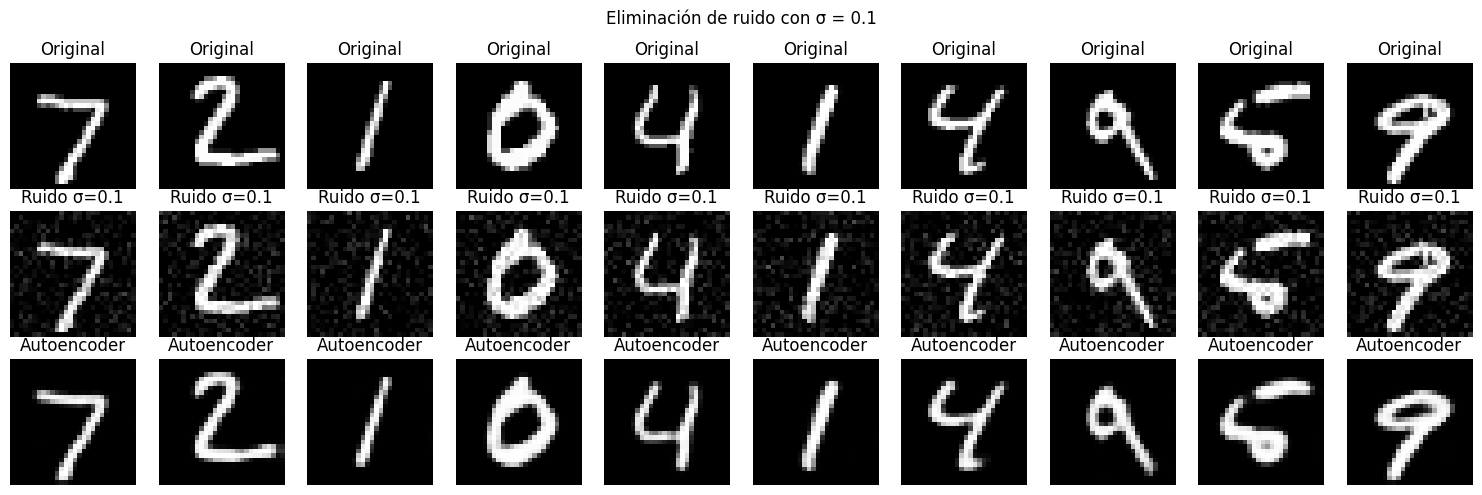


===== Entrenando con σ = 0.3 =====


σ=0.3 | Epoch 1/10 | Loss (MSE): 0.0308


σ=0.3 | Epoch 2/10 | Loss (MSE): 0.0100


σ=0.3 | Epoch 3/10 | Loss (MSE): 0.0081


σ=0.3 | Epoch 4/10 | Loss (MSE): 0.0072


σ=0.3 | Epoch 5/10 | Loss (MSE): 0.0068


... (2 outputs left out)

σ=0.3 | Epoch 8/10 | Loss (MSE): 0.0061


σ=0.3 | Epoch 9/10 | Loss (MSE): 0.0060


σ=0.3 | Epoch 10/10 | Loss (MSE): 0.0059


Test σ=0.3: MSE con ruido = 0.0466 | MSE reconstruida = 0.0057


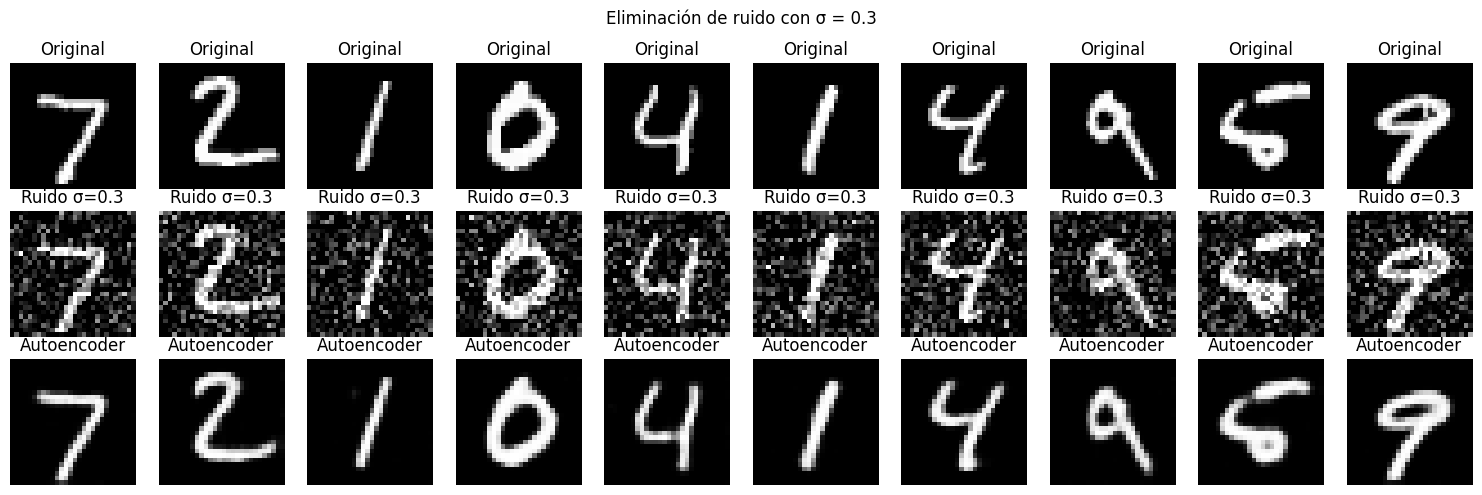


===== Entrenando con σ = 0.5 =====


σ=0.5 | Epoch 1/10 | Loss (MSE): 0.0373


σ=0.5 | Epoch 2/10 | Loss (MSE): 0.0157


σ=0.5 | Epoch 3/10 | Loss (MSE): 0.0135


σ=0.5 | Epoch 4/10 | Loss (MSE): 0.0125


σ=0.5 | Epoch 5/10 | Loss (MSE): 0.0120


... (2 outputs left out)

σ=0.5 | Epoch 8/10 | Loss (MSE): 0.0112


σ=0.5 | Epoch 9/10 | Loss (MSE): 0.0111


σ=0.5 | Epoch 10/10 | Loss (MSE): 0.0109


Test σ=0.5: MSE con ruido = 0.1156 | MSE reconstruida = 0.0107


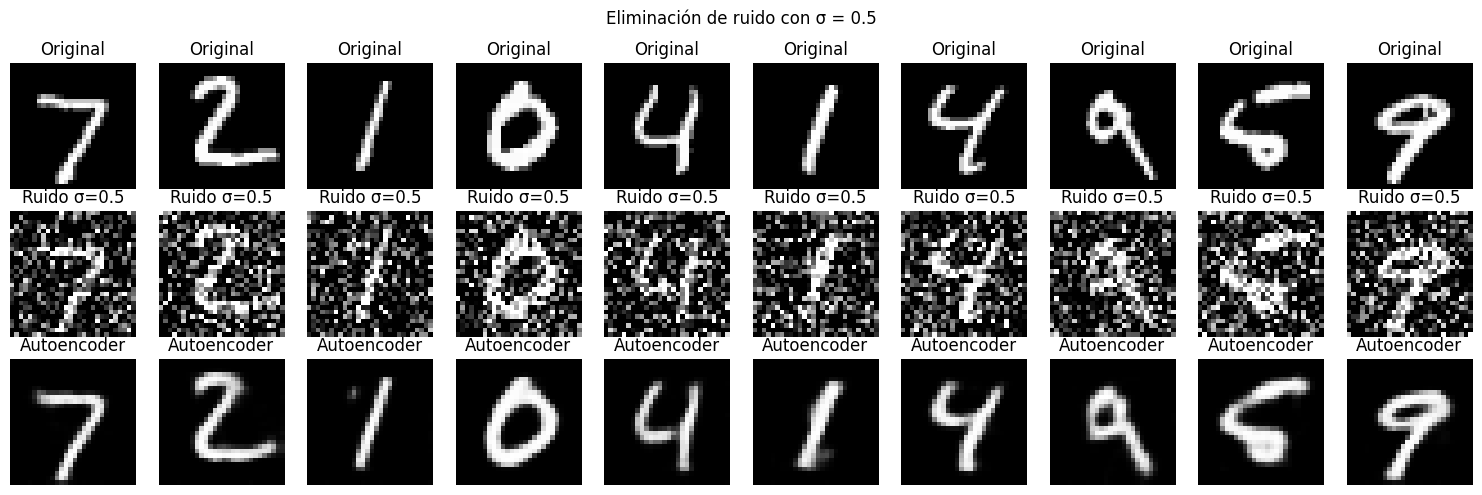


===== Entrenando con σ = 0.7 =====


σ=0.7 | Epoch 1/10 | Loss (MSE): 0.0429


σ=0.7 | Epoch 2/10 | Loss (MSE): 0.0229


σ=0.7 | Epoch 3/10 | Loss (MSE): 0.0203


σ=0.7 | Epoch 4/10 | Loss (MSE): 0.0192


σ=0.7 | Epoch 5/10 | Loss (MSE): 0.0186


... (2 outputs left out)

σ=0.7 | Epoch 8/10 | Loss (MSE): 0.0176


σ=0.7 | Epoch 9/10 | Loss (MSE): 0.0174


σ=0.7 | Epoch 10/10 | Loss (MSE): 0.0173


Test σ=0.7: MSE con ruido = 0.1813 | MSE reconstruida = 0.0169


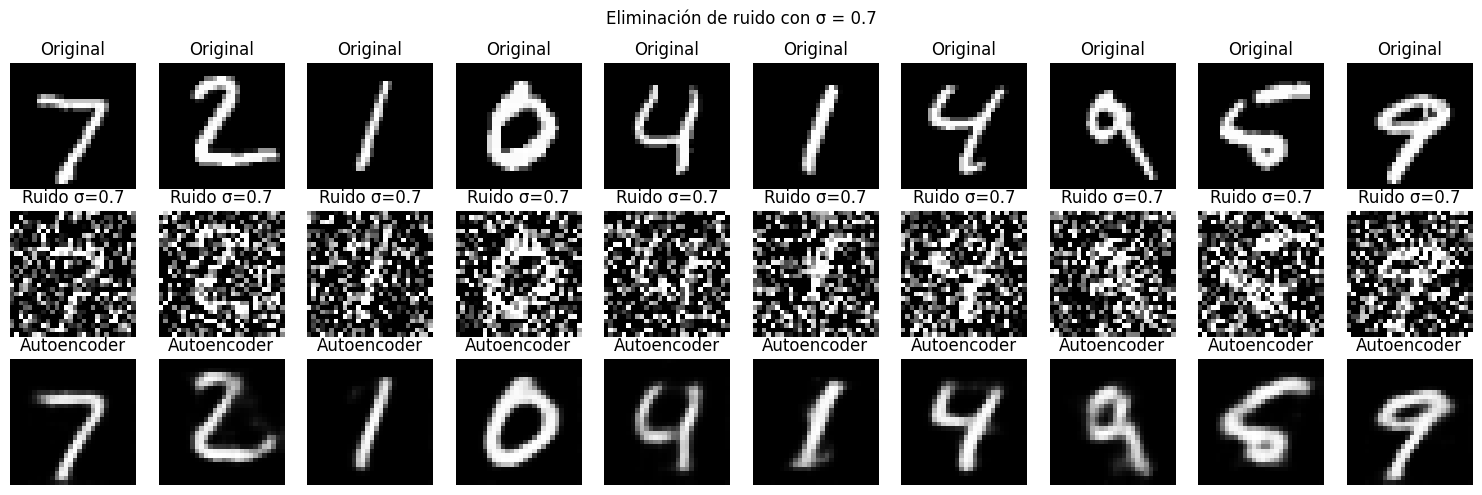


===== Entrenando con σ = 1.0 =====


σ=1.0 | Epoch 1/10 | Loss (MSE): 0.0508


σ=1.0 | Epoch 2/10 | Loss (MSE): 0.0331


σ=1.0 | Epoch 3/10 | Loss (MSE): 0.0308


σ=1.0 | Epoch 4/10 | Loss (MSE): 0.0296


σ=1.0 | Epoch 5/10 | Loss (MSE): 0.0289


... (2 outputs left out)

σ=1.0 | Epoch 8/10 | Loss (MSE): 0.0278


σ=1.0 | Epoch 9/10 | Loss (MSE): 0.0276


σ=1.0 | Epoch 10/10 | Loss (MSE): 0.0274


Test σ=1.0: MSE con ruido = 0.2524 | MSE reconstruida = 0.0270


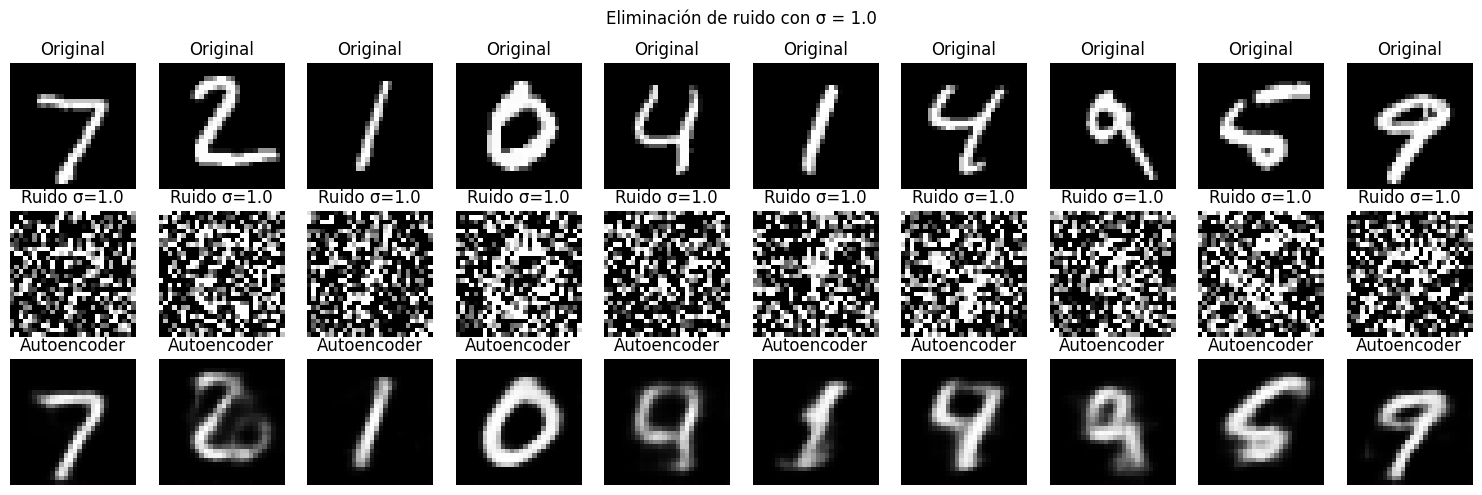

In [8]:
niveles_ruido = [0.1, 0.3, 0.5, 0.7, 1.0]
resultados = {}

for sigma in niveles_ruido:
    print(f"\n===== Entrenando con σ = {sigma} =====")
    torch.manual_seed(42)  # misma inicialización para todos los modelos
    modelo = AutoencoderCNN().to(device)
    entrenar(modelo, sigma)

    mse_ruido, mse_recon = evaluar(modelo, sigma)
    resultados[sigma] = (mse_ruido, mse_recon)
    print(f"Test σ={sigma}: MSE con ruido = {mse_ruido:.4f} | MSE reconstruida = {mse_recon:.4f}")

    visualizar_ruido(modelo, sigma)

## Resumen de resultados

    σ |  MSE con ruido |  MSE autoencoder
------------------------------------------
  0.1 |         0.0054 |           0.0028
  0.3 |         0.0466 |           0.0057
  0.5 |         0.1156 |           0.0107
  0.7 |         0.1813 |           0.0169
  1.0 |         0.2524 |           0.0270


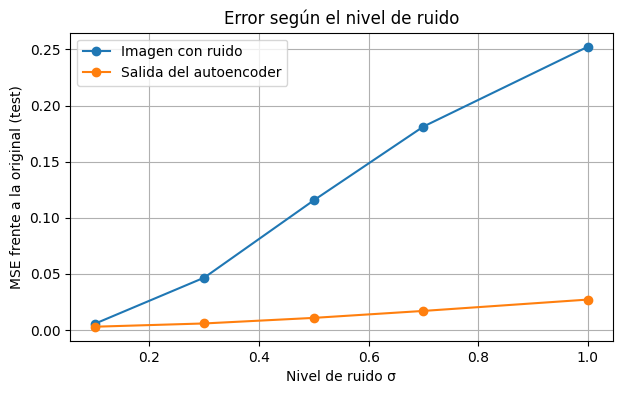

In [9]:
print(f"{'σ':>5} | {'MSE con ruido':>14} | {'MSE autoencoder':>16}")
print("-" * 42)
for sigma, (mse_ruido, mse_recon) in resultados.items():
    print(f"{sigma:>5} | {mse_ruido:>14.4f} | {mse_recon:>16.4f}")

plt.figure(figsize=(7, 4))
plt.plot(niveles_ruido, [resultados[s][0] for s in niveles_ruido], 'o-', label="Imagen con ruido")
plt.plot(niveles_ruido, [resultados[s][1] for s in niveles_ruido], 'o-', label="Salida del autoencoder")
plt.xlabel("Nivel de ruido σ")
plt.ylabel("MSE frente a la original (test)")
plt.title("Error según el nivel de ruido")
plt.legend()
plt.grid(True)
plt.show()

## Conclusiones

| σ | MSE con ruido | MSE autoencoder |
|---|---|---|
| 0.1 | 0.0054 | 0.0028 |
| 0.3 | 0.0466 | 0.0057 |
| 0.5 | 0.1156 | 0.0107 |
| 0.7 | 0.1813 | 0.0169 |
| 1.0 | 0.2524 | 0.0270 |

- Con todos los niveles, el autoencoder reduce mucho el error respecto a la imagen con ruido: en torno a **10 veces menos** a partir de σ = 0.3.
- El error de la salida crece con σ, aunque mucho más despacio que el de la entrada: cuanto más ruido, más información del dígito se pierde y más difícil es reconstruirlo.
- Con σ pequeño (0.1, 0.3) la reconstrucción es casi idéntica a la original. Con σ = 1.0 el dígito apenas se ve en la entrada, pero el autoencoder lo recupera, algo más borroso. En algunos casos lo confunde con un dígito parecido (por ejemplo, un 4 que sale como un 9).
- La borrosidad de la salida se debe a que el espacio latente es de 64 dimensiones y a la pérdida MSE, que favorece promediar los píxeles dudosos.